# AgriOptima: Post-harvest loss

Predict a published loss percentage from state, crop and stage. The study is aggregated and covers one year; a favourable split is not independent farm-level validation.

Run each cell in order. This notebook trains its own evaluation model and does not overwrite application artifacts.

## 1. Import libraries and find the project
Pandas reads tables; NumPy handles numbers; Matplotlib draws figures.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when Jupyter starts in the project root or this notebook folder.
ROOT = Path.cwd()
if not (ROOT / 'DataSets').exists():
    ROOT = ROOT.parent
assert (ROOT / 'DataSets').exists(), 'Open Jupyter in the project folder.'

## 2. Read, inspect and clean raw data
The source CSVs remain unchanged. Invalid rows and duplicate handling are visible below. Earlier audit records are preserved in the recovery copy outside this project.

In [2]:
raw = pd.read_csv(ROOT / 'DataSets/Food Loss/post_harvest_loss_2022_state_stage.csv')
display(raw.head())
print('Raw rows:', len(raw))
features = ['state', 'crop', 'loss_type', 'stage']
data = raw[features + ['loss_percentage']].copy()
for column in features:
    data[column] = data[column].astype('string').str.strip()
data['loss_percentage'] = pd.to_numeric(data['loss_percentage'], errors='coerce')
valid = data['loss_percentage'].between(0, 100)
for column in features:
    valid = valid & (data[column].str.len().fillna(0) > 0)
data = data.loc[valid].drop_duplicates().reset_index(drop=True)
print('Clean rows:', len(data))

,year,state,crop,loss_type,stage,loss_percentage,source_pdf_page,source_table,source_row
0,2022,Andhra Pradesh,Bajra,Farm Operations,Harvesting,1.17,267,1,6
1,2022,Andhra Pradesh,Bajra,Farm Operations,Collection,0.41,267,1,6
2,2022,Andhra Pradesh,Bajra,Farm Operations,Threshing,1.69,267,1,6
3,2022,Andhra Pradesh,Bajra,Farm Operations,Winnowing/Cleaning,0.15,267,1,6
4,2022,Andhra Pradesh,Bajra,Farm Operations,Drying,0.21,267,1,6


Raw rows: 1865
Clean rows: 1865


### Look at the data
This overview describes the dataset. It is not a prediction result.

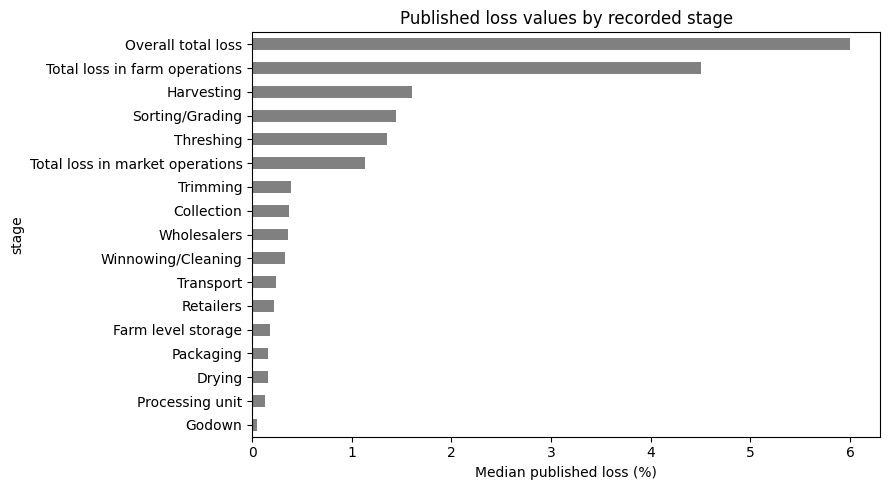

In [3]:
data.groupby('stage')['loss_percentage'].median().sort_values().plot.barh(figsize=(9, 5), color='gray')
plt.xlabel('Median published loss (%)')
plt.title('Published loss values by recorded stage')
plt.tight_layout()
plt.show()

Each bar is the middle published value for that stage across available records. Overall totals and individual stages are different types of records: do not add the bars or treat them as a causal comparison.

## 3. Split related records and tune the forest
Every stage of one state-crop combination stays together. First reserve the historical test groups. Inside training, use a second grouped split to compare forest criteria, leaf sizes and depths. Smaller leaves can represent detailed categories. Absolute-error splits align the tree objective with MAE. Only validation selects settings. This historical test has already been inspected, so it is not a new external test.

In [4]:

from pathlib import Path
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [5]:
features = ["state", "crop", "loss_type", "stage"]

In [6]:
# 2. Keep every stage of a state/crop combination together in the same split.
groups = data["state"] + "|" + data["crop"]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_indices, test_indices = next(splitter.split(data, groups=groups))
train = data.iloc[train_indices]
test = data.iloc[test_indices]

In [7]:
# 3. Turn text categories into numbers and train the forest.
text_steps = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preparation = ColumnTransformer([("categories", text_steps, features)])
forest = RandomForestRegressor(
    n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=1
)
model = Pipeline([("preprocessor", preparation), ("model", forest)])
# Tune only inside the training groups. The historical test stays separate.
from sklearn.base import clone
inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=17)
fit_indices, validation_indices = next(inner.split(train, groups=groups.iloc[train_indices]))
fit_data = train.iloc[fit_indices]
validation_data = train.iloc[validation_indices]
candidates = []
for criterion in ['squared_error', 'absolute_error']:
    for leaf in [1, 2, 5, 10]:
        for depth in [None, 12]:
            candidate = clone(model).set_params(model__criterion=criterion,
                model__min_samples_leaf=leaf, model__max_depth=depth)
            candidate.fit(fit_data[features], fit_data['loss_percentage'])
            error = mean_absolute_error(validation_data['loss_percentage'], candidate.predict(validation_data[features]))
            candidates.append({'criterion': criterion, 'min_samples_leaf': leaf,
                'max_depth': depth, 'validation_mae': error})
tuning = pd.DataFrame(candidates)
display(tuning.sort_values('validation_mae'))
best = min(candidates, key=lambda row: row['validation_mae'])
model.set_params(model__criterion=best['criterion'], model__min_samples_leaf=best['min_samples_leaf'],
    model__max_depth=best['max_depth'])
model.fit(train[features], train['loss_percentage'])

,criterion,min_samples_leaf,max_depth,validation_mae
8,absolute_error,1,NaN,0.405771
0,squared_error,1,NaN,0.406426
1,squared_error,1,12.0,0.438718
9,absolute_error,1,12.0,0.439402
10,absolute_error,2,NaN,0.450911
2,squared_error,2,NaN,0.454169
3,squared_error,2,12.0,0.463394
11,absolute_error,2,12.0,0.464106
12,absolute_error,5,NaN,0.497504
14,absolute_error,10,NaN,0.503335


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categories',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['state', 'crop', 'loss_type',
                                                   'stage'])])),
                ('model',
                 RandomForestRegressor(criterion='absolute_error',
                                       n_estimators=200, n_jobs=1,
                                       random_state=42))])

In [8]:
# 4. Compare with a constant prediction equal to the training median loss.
predictions = model.predict(test[features])
actual = test["loss_percentage"]
baseline = [train["loss_percentage"].median()] * len(test)
print("Model MAE (percentage points):", mean_absolute_error(actual, predictions))
print("Baseline MAE:", mean_absolute_error(actual, baseline))
print("RMSE:", mean_squared_error(actual, predictions) ** 0.5)
# Only one study year is represented. This split alone is not external validation.
# A stronger baseline predicts the training median for each loss-type/stage pair.
stage_medians = train.groupby(['loss_type', 'stage'])['loss_percentage'].median()
stage_baseline = [stage_medians.get((row.loss_type, row.stage), train['loss_percentage'].median())
                  for row in test.itertuples()]
comparison = pd.DataFrame([
    {'method':'Constant training median', 'mae':mean_absolute_error(actual, baseline)},
    {'method':'Training stage median', 'mae':mean_absolute_error(actual, stage_baseline)},
    {'method':'Validation-tuned Random Forest', 'mae':mean_absolute_error(actual, predictions)}])
display(comparison)
# Overall totals are harder than individual stage values. Report both.
record_type = np.where(test['stage'].eq('Overall total loss'), 'Overall total',
    np.where(test['stage'].str.contains('total', case=False), 'Subtotal', 'Individual stage'))
details = pd.DataFrame({'actual':np.asarray(actual), 'prediction':predictions,
    'record_type':record_type})
details['absolute_error'] = abs(details['actual'] - details['prediction'])
display(details.groupby('record_type')['absolute_error'].agg(['count','mean']))
from pathlib import Path
result_dir = ROOT / 'results/post_harvest_loss'
result_dir.mkdir(parents=True, exist_ok=True)
comparison.to_csv(result_dir / 'metrics.csv', index=False)
tuning.to_csv(result_dir / 'validation_tuning.csv', index=False)
details.to_csv(result_dir / 'test_predictions.csv', index=False)
details.groupby('record_type')['absolute_error'].agg(['count','mean']).to_csv(result_dir / 'errors_by_record_type.csv')
print('Overlapping state-crop groups:', len(set(groups.iloc[train_indices]) & set(groups.iloc[test_indices])))


Model MAE (percentage points): 0.3441911016326531
Baseline MAE: 0.9937020408163265
RMSE: 0.6180179408305954


,method,mae
0,Constant training median,0.993702
1,Training stage median,0.355590
2,Validation-tuned Random Forest,0.344191


,count,mean
record_type,,
Individual stage,398,0.227651
Overall total,28,1.039850
Subtotal,64,0.764573


Overlapping state-crop groups: 0


## 4. Figures and interpretation
These figures use held-out predictions when labels exist. For soil, they describe the held-out groups or scores.

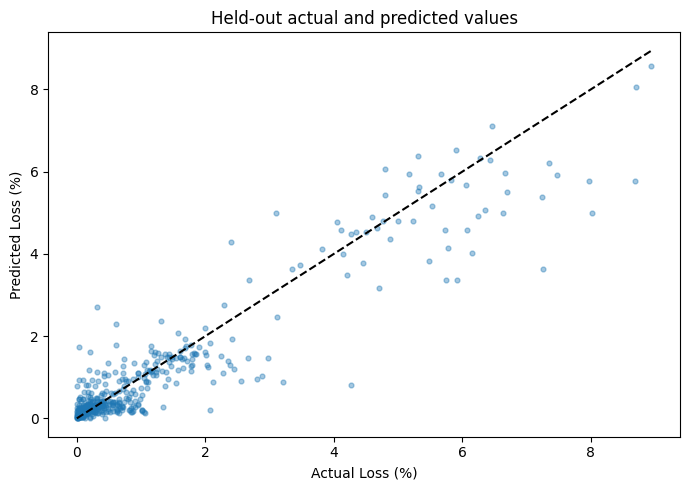

,actual,prediction
0,0.74,1.454750
1,0.39,0.342950
2,2.67,1.461850
3,0.56,0.182300
4,0.62,0.192815


In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(actual, predictions, alpha=0.4, s=12)
low, high = min(actual.min(), predictions.min()), max(actual.max(), predictions.max())
plt.plot([low, high], [low, high], 'k--')
plt.xlabel('Actual Loss (%)')
plt.ylabel('Predicted Loss (%)')
plt.title('Held-out actual and predicted values')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'actual': np.asarray(actual)[:5], 'prediction': predictions[:5]}))

The dashed line is a perfect prediction. Points away from it are errors. MAE gives their average absolute size; the table shows five held-out examples.

## 5. Save the evaluated model
The bundle keeps the fitted preprocessing and model together. The website uses a copy in backend/saved_models/post_harvest_loss.joblib. It estimates a published overall loss separately from the original dataset reference. Unsupported crop labels return no model estimate.

In [10]:
import joblib
output = ROOT / 'saved_models'
output.mkdir(exist_ok=True)
bundle = {'model': model, 'features': features, 'status':'Historical study-value model; grouped holdout, not farm validation', 'validation_parameters':best}
joblib.dump(bundle, output / '04_post_harvest_loss.joblib')
print('Learning artifact saved separately.')

Learning artifact saved separately.


## 6. Viva summary and limitations
Predict a published loss percentage from state, crop and stage. The study is aggregated and covers one year; a favourable split is not independent farm-level validation.

Explain: source and target, cleaning choices, split, preprocessing, algorithm, metric, baseline (if applicable), and one limitation. Fitted preprocessing must also be used for new requests. No custom Python functions or classes are defined in this notebook.

The overall-total error must be read separately from the combined MAE. Model improvement on this reused historical test is not a guarantee for future farms. The additional FAO India records use different studies, years, regional detail and loss definitions. The farm workbook has no compatible post-harvest-loss target, so neither source is silently merged into training. Extra copies of existing rows would not create new evidence.